You are given an integer array nums. You can choose exactly one index (0-indexed) and remove the element. Notice that the index of the elements may change after the removal.

For example, if nums = [6,1,7,4,1]:

Choosing to remove index 1 results in nums = [6,7,4,1].
Choosing to remove index 2 results in nums = [6,1,4,1].
Choosing to remove index 4 results in nums = [6,1,7,4].
An array is fair if the sum of the odd-indexed values equals the sum of the even-indexed values.

Return the number of indices that you could choose such that after the removal, nums is fair.



Example 1:

Input: nums = [2,1,6,4]
Output: 1
Explanation:
Remove index 0: [1,6,4] -> Even sum: 1 + 4 = 5. Odd sum: 6. Not fair.
Remove index 1: [2,6,4] -> Even sum: 2 + 4 = 6. Odd sum: 6. Fair.
Remove index 2: [2,1,4] -> Even sum: 2 + 4 = 6. Odd sum: 1. Not fair.
Remove index 3: [2,1,6] -> Even sum: 2 + 6 = 8. Odd sum: 1. Not fair.
There is 1 index that you can remove to make nums fair.
Example 2:

Input: nums = [1,1,1]
Output: 3
Explanation: You can remove any index and the remaining array is fair.
Example 3:

Input: nums = [1,2,3]
Output: 0
Explanation: You cannot make a fair array after removing any index.


Constraints:

1 <= nums.length <= 105
1 <= nums[i] <= 104

In [ ]:
fun waysToMakeFair(nums: IntArray): Int {
    val hashMap = HashMap<Int, IntArray>()
    var evenSum = 0
    var oddSum = 0

    for (i in nums.indices) {
        if (i % 2 == 0) evenSum+=nums[i]
        else oddSum+=nums[i]
        hashMap.put(i, intArrayOf(evenSum, oddSum))
    }

    var count = 0

    for (i in nums.indices) {
        val prevSums = hashMap.getOrDefault(i, intArrayOf(0, 0))
        var prevEven = prevSums[0]
        var prevOdd = prevSums[1]

        if (i % 2 == 0) prevEven -= nums[i]
        else prevOdd -= nums[i]

        if (prevEven + (oddSum-prevSums[1]) == prevOdd + (evenSum - prevSums[0])) {
            count++
        }

    }

    return count
}

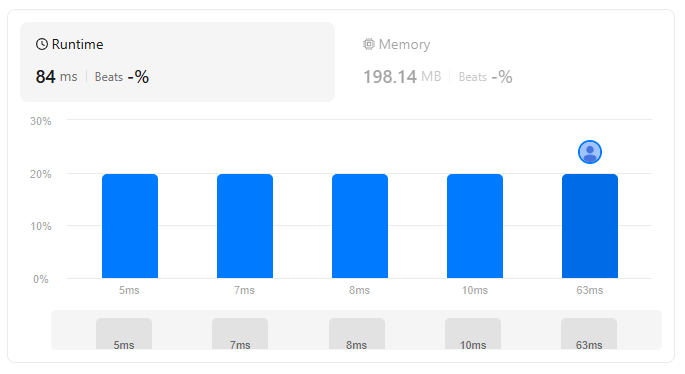

In [ ]:
fun waysToMakeFair(nums: IntArray): Int {
    val right = IntArray(2)
    val left = IntArray(2)

    nums.forEachIndexed { i, num ->
        right[i%2] += num
    }

    var count = 0

    for (i in nums.indices) {
        right[i%2] -= nums[i]

        if (left[0] + right[1] == left[1]+right[0]) count++

        left[i%2] += nums[i]
    }

    return count
}

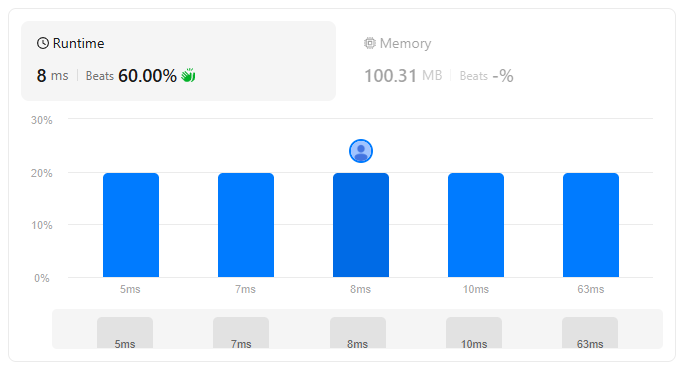